# Setup

In [1]:
import sys
from pathlib import Path

# Make eval_utils importable whether the kernel starts in repo root or notebooks/.
_here = Path.cwd()
for cand in (_here, _here / "notebooks", _here.parent):
    if (cand / "eval_utils.py").exists():
        sys.path.insert(0, str(cand))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support

import eval_utils as ev
from eval_utils import (
    SPLITS, NORMAL_SPLIT, SHIFT_SPLIT, ROBUST_METRICS, METRIC_LABELS,
    SPLIT_COLORS, CLASS_NAMES_FULL,
)

ev.apply_style()
FIG_DIR = ev.make_fig_dir("figures")
TABLE_DIR = ev.make_table_dir("tables")  # xlsx exports for PowerPoint/Word
SAVE_FIGS = True

In [2]:
# Edit here to point elsewhere or widen the selection.
ENTITY, PROJECT, RUN_TAG = ev.ENTITY, ev.PROJECT, ev.RUN_TAG   # ("trash-busters", "trash-busters", "core")

runs = ev.fetch_runs(ENTITY, PROJECT, RUN_TAG)
ev.describe_runs(runs)

# Core metrics + per-sample confusion frames (shared by both notebooks).
metrics_long, confusion_frames = ev.build_metrics(runs)

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.


Found 8 run(s):
  - baseline_final                 model=baseline       classes=6 state=finished tags=['core']
  - mlp_mixer_final                model=mlp_mixer      classes=6 state=finished tags=['core']
  - convnext_tiny_final            model=convnext_tiny  classes=6 state=finished tags=['core']
  - deit_final                     model=deit           classes=6 state=finished tags=['core']
  - baseline_final_softmax         model=baseline       classes=6 state=finished tags=['core', 'softmax']
  - mlp_mixer_final_softmax        model=mlp_mixer      classes=6 state=finished tags=['core', 'softmax']
  - convnext_tiny_final_softmax    model=convnext_tiny  classes=6 state=finished tags=['core', 'softmax']
  - deit_final_softmax             model=deit           classes=6 state=finished tags=['core', 'softmax']


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


note: no confusion CSV for baseline_final_softmax/test; used logged scalars
note: no confusion CSV for baseline_final_softmax/custom_test; used logged scalars
note: no confusion CSV for mlp_mixer_final_softmax/test; used logged scalars
note: no confusion CSV for mlp_mixer_final_softmax/custom_test; used logged scalars
note: no confusion CSV for convnext_tiny_final_softmax/test; used logged scalars
note: no confusion CSV for convnext_tiny_final_softmax/custom_test; used logged scalars
note: no confusion CSV for deit_final_softmax/test; used logged scalars
note: no confusion CSV for deit_final_softmax/custom_test; used logged scalars


## precision / recall / F1

In [3]:
per_class_rows = []
for run in runs:
    names = ev.run_class_names(run)
    labels = list(range(len(names)))
    for split in SPLITS:
        df = confusion_frames.get((run.name, split))
        if df is None:
            continue
        p, r, f1, sup = precision_recall_fscore_support(
            df["true_label"], df["predicted_label"], labels=labels, zero_division=0)
        for i, cls in enumerate(names):
            per_class_rows.append({
                "model": ev.model_label(run), "split": split, "split_label": SPLITS[split],
                "class": cls, "precision": p[i], "recall": r[i], "f1": f1[i], "support": int(sup[i]),
            })
per_class = pd.DataFrame(per_class_rows)
ev.show_table(per_class, "per_class_precision_recall_f1", TABLE_DIR)

,model,split,split_label,class,precision,recall,f1,support
0,baseline,test,Normal test,cardboard,0.8467,0.8723,0.8593,728
1,baseline,test,Normal test,glass,0.8565,0.8200,0.8379,750
2,baseline,test,Normal test,metal,0.7691,0.8573,0.8108,750
3,baseline,test,Normal test,paper,0.7462,0.7213,0.7336,750
4,baseline,test,Normal test,plastic,0.7368,0.6907,0.7130,750
5,baseline,test,Normal test,trash,0.8150,0.8107,0.8128,750
6,baseline,custom_test,Custom (domain shift),cardboard,0.6400,0.3478,0.4507,46
7,baseline,custom_test,Custom (domain shift),glass,0.3500,0.1186,0.1772,59
8,baseline,custom_test,Custom (domain shift),metal,0.4000,0.2273,0.2899,44
9,baseline,custom_test,Custom (domain shift),paper,0.4286,0.0455,0.0822,66


saved tables\per_class_precision_recall_f1.xlsx


,model,split,split_label,class,precision,recall,f1,support
0,baseline,test,Normal test,cardboard,0.8467,0.8723,0.8593,728
1,baseline,test,Normal test,glass,0.8565,0.8200,0.8379,750
2,baseline,test,Normal test,metal,0.7691,0.8573,0.8108,750
3,baseline,test,Normal test,paper,0.7462,0.7213,0.7336,750
4,baseline,test,Normal test,plastic,0.7368,0.6907,0.7130,750
5,baseline,test,Normal test,trash,0.8150,0.8107,0.8128,750
6,baseline,custom_test,Custom (domain shift),cardboard,0.6400,0.3478,0.4507,46
7,baseline,custom_test,Custom (domain shift),glass,0.3500,0.1186,0.1772,59
8,baseline,custom_test,Custom (domain shift),metal,0.4000,0.2273,0.2899,44
9,baseline,custom_test,Custom (domain shift),paper,0.4286,0.0455,0.0822,66


saved figures\per_class_f1_normal.png


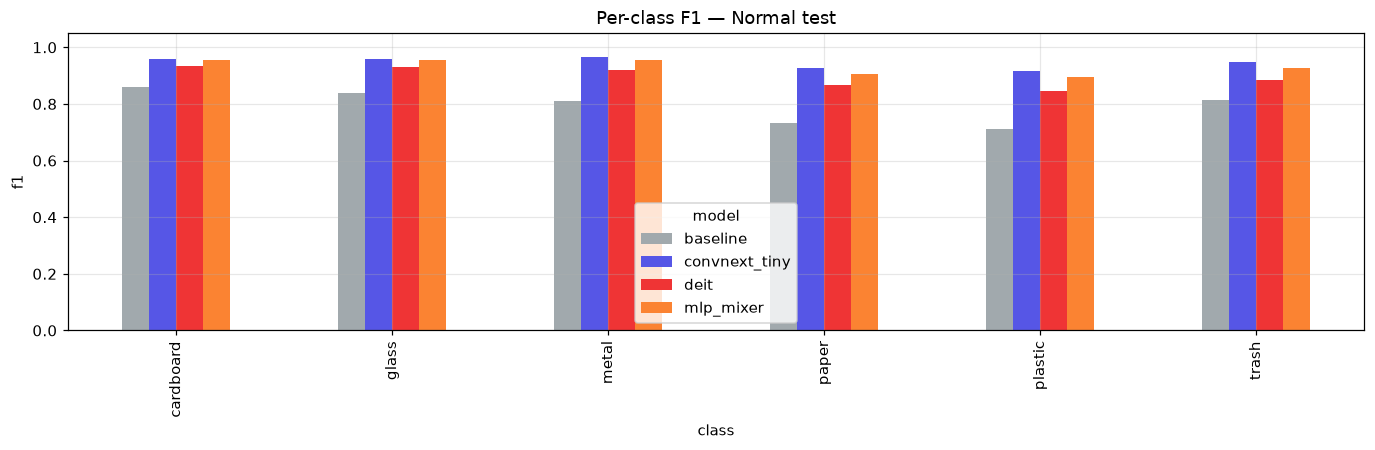

saved figures\per_class_f1_shift.png


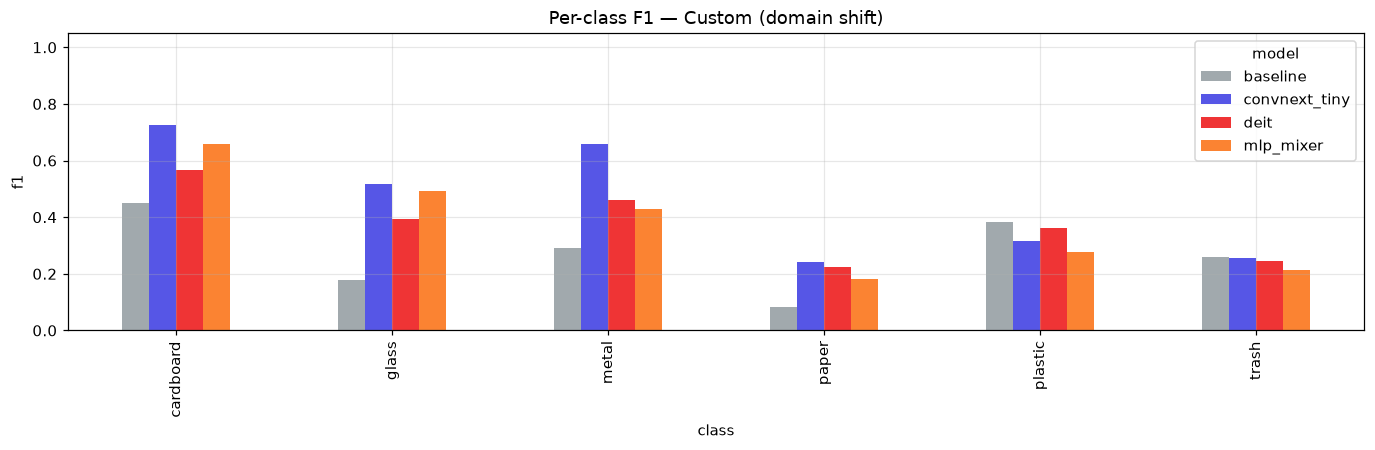

In [4]:
def per_class_f1_bar(split, fname):
    sub = per_class[per_class.split == split]
    if sub.empty:
        print(f"(no per-class data for {split})"); return
    pivot = sub.pivot_table(index="class", columns="model", values="f1")
    ax = pivot.plot(kind="bar", figsize=(1.6 * len(pivot) + 3, 4.2), color=ev.model_palette(pivot.columns))
    ax.set_ylabel("f1"); ax.set_ylim(0, 1.05)
    ax.set_title(f"Per-class F1 — {SPLITS[split]}"); ax.legend(title="model")
    fig = ax.get_figure(); fig.tight_layout()
    ev.savefig(fig, fname, FIG_DIR, SAVE_FIGS); plt.show()


per_class_f1_bar(NORMAL_SPLIT, "per_class_f1_normal")
per_class_f1_bar(SHIFT_SPLIT, "per_class_f1_shift")

## gap 

,baseline,mlp_mixer,convnext_tiny,deit
class,,,,
cardboard,0.4090,0.2980,0.2320,0.3660
glass,0.6610,0.4600,0.4410,0.5340
metal,0.5210,0.5250,0.3050,0.4590
paper,0.6510,0.7250,0.6880,0.6410
plastic,0.3310,0.6160,0.5990,0.4830
trash,0.5530,0.7120,0.6900,0.6400


saved tables\per_class_domain_gap.xlsx
saved figures\per_class_domain_gap.png


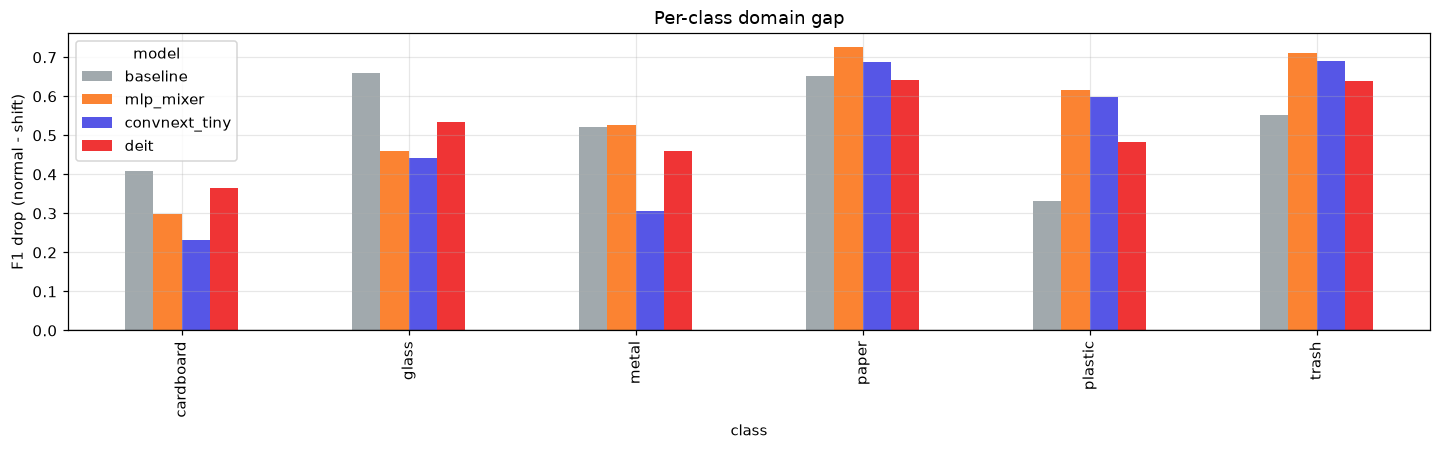

In [5]:
f1_piv = per_class.pivot_table(index=["class"], columns=["model", "split"], values="f1")
gap_cols = {}
for model in per_class.model.unique():
    if (model, NORMAL_SPLIT) in f1_piv.columns and (model, SHIFT_SPLIT) in f1_piv.columns:
        gap_cols[model] = f1_piv[(model, NORMAL_SPLIT)] - f1_piv[(model, SHIFT_SPLIT)]
per_class_gap = pd.DataFrame(gap_cols)
if not per_class_gap.empty:
    ev.show_table(per_class_gap, "per_class_domain_gap", TABLE_DIR, decimals=3)
    ax = per_class_gap.plot(kind="bar", figsize=(1.7 * len(per_class_gap) + 3, 4.2), color=ev.model_palette(per_class_gap.columns))
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylabel("F1 drop (normal - shift)"); ax.set_title("Per-class domain gap")
    ax.legend(title="model")
    fig = ax.get_figure(); fig.tight_layout()
    ev.savefig(fig, "per_class_domain_gap", FIG_DIR, SAVE_FIGS); plt.show()
else:
    print("(need both splits' confusion CSVs to compute per-class domain gap)")

## conf matrices

saved figures\confusion_baseline_final.png


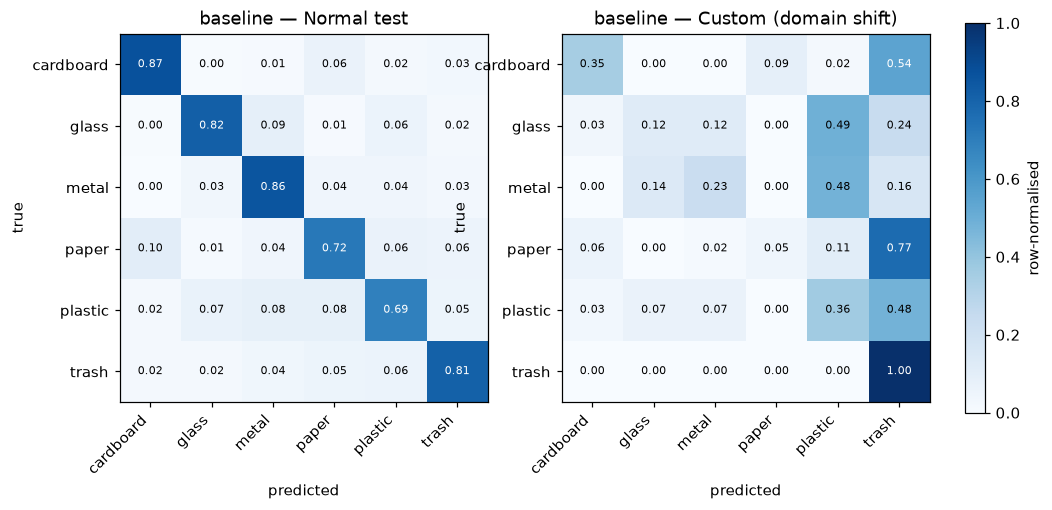

saved figures\confusion_mlp_mixer_final.png


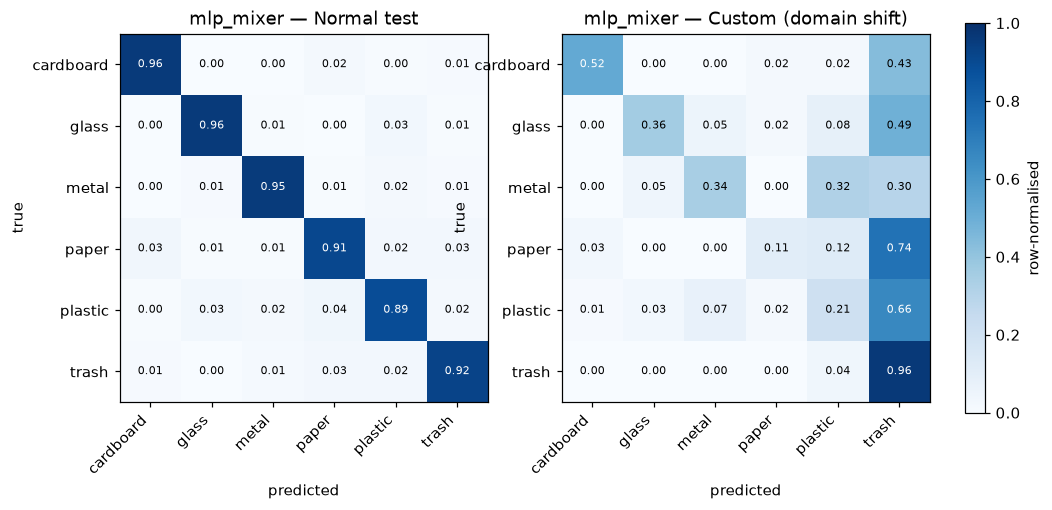

saved figures\confusion_convnext_tiny_final.png


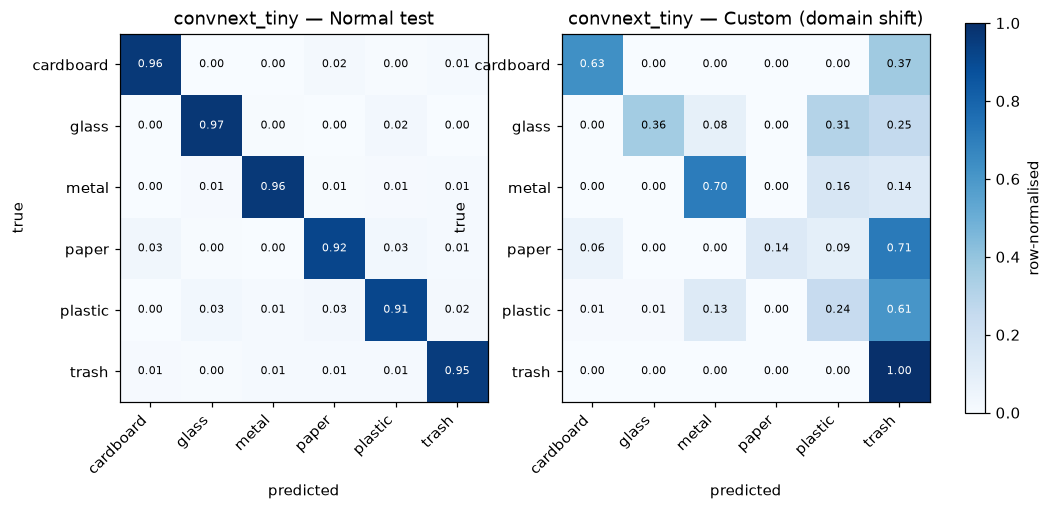

saved figures\confusion_deit_final.png


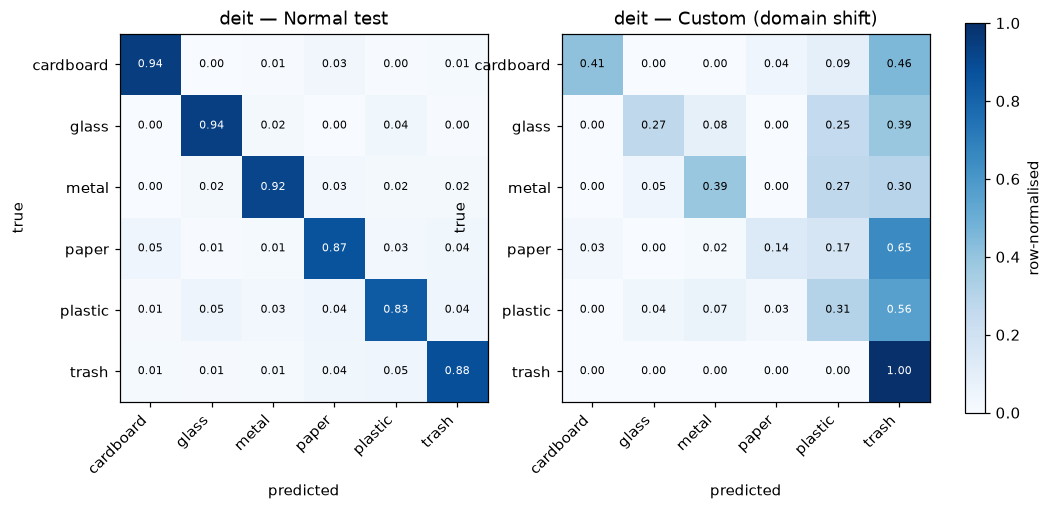

(no confusion artifacts for baseline_final_softmax)
(no confusion artifacts for mlp_mixer_final_softmax)
(no confusion artifacts for convnext_tiny_final_softmax)
(no confusion artifacts for deit_final_softmax)


In [6]:
for run in runs:
    names = ev.run_class_names(run); labels = list(range(len(names)))
    avail = [s for s in SPLITS if confusion_frames.get((run.name, s)) is not None]
    if not avail:
        print(f"(no confusion artifacts for {run.name})"); continue
    fig, axes = plt.subplots(1, len(avail), figsize=(5.2 * len(avail), 4.6))
    axes = np.atleast_1d(axes)
    for ax, split in zip(axes, avail):
        df = confusion_frames[(run.name, split)]
        cm = confusion_matrix(df["true_label"], df["predicted_label"], labels=labels)
        im = ev.plot_confusion(cm, names, f"{ev.model_label(run)} — {SPLITS[split]}", ax)
    fig.colorbar(im, ax=list(axes), fraction=0.046, pad=0.04, label="row-normalised")
    ev.savefig(fig, f"confusion_{run.name}", FIG_DIR, SAVE_FIGS); plt.show()

## auroc per class

(needs softmax data)

In [7]:
# AUROC/ECE come from the separate `softmax` runs (scripts/log_prob_metrics.py).
prob_runs = ev.fetch_softmax_runs()
if not prob_runs:
    print("No 'softmax' runs found -- run scripts/log_prob_metrics.py first. "
          "Skipping probability metrics.")
    prob_metrics = pd.DataFrame()
else:
    print(f"Found {len(prob_runs)} softmax run(s): {[r.name for r in prob_runs]}")
    prob_metrics = ev.build_probability_metrics(prob_runs)
prob_metrics

Found 4 softmax run(s): ['baseline_final_softmax', 'mlp_mixer_final_softmax', 'convnext_tiny_final_softmax', 'deit_final_softmax']


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


,run,model,source_run_name,split,split_label,auroc_macro_ovr,ece,sce,auroc_cardboard,auroc_glass,auroc_metal,auroc_paper,auroc_plastic,auroc_trash
0,baseline_final_softmax,baseline,baseline_final,test,Normal test,0.9626,0.0228,-0.0226,0.9821,0.9785,0.9683,0.9445,0.9362,0.9662
1,baseline_final_softmax,baseline,baseline_final,custom_test,Custom (domain shift),0.8053,0.3704,0.3704,0.8627,0.8262,0.8020,0.7281,0.6607,0.9523
2,mlp_mixer_final_softmax,mlp_mixer,mlp_mixer_final,test,Normal test,0.9947,0.0404,0.0398,0.9973,0.9980,0.9979,0.9899,0.9905,0.9949
3,mlp_mixer_final_softmax,mlp_mixer,mlp_mixer_final,custom_test,Custom (domain shift),0.7797,0.5333,0.5333,0.7298,0.8429,0.8632,0.6856,0.6570,0.8994
4,convnext_tiny_final_softmax,convnext_tiny,convnext_tiny_final,test,Normal test,0.9961,0.0238,0.0224,0.9975,0.9985,0.9982,0.9928,0.9928,0.9965
5,convnext_tiny_final_softmax,convnext_tiny,convnext_tiny_final,custom_test,Custom (domain shift),0.8527,0.4590,0.4575,0.8935,0.9282,0.9172,0.7483,0.6984,0.9307
6,deit_final_softmax,deit,deit_final,test,Normal test,0.9861,0.0398,0.0387,0.9950,0.9929,0.9927,0.9790,0.9718,0.9852
7,deit_final_softmax,deit,deit_final,custom_test,Custom (domain shift),0.7836,0.4986,0.4921,0.7987,0.8135,0.8204,0.7480,0.6591,0.8620


saved figures\per_class_auroc_test.png


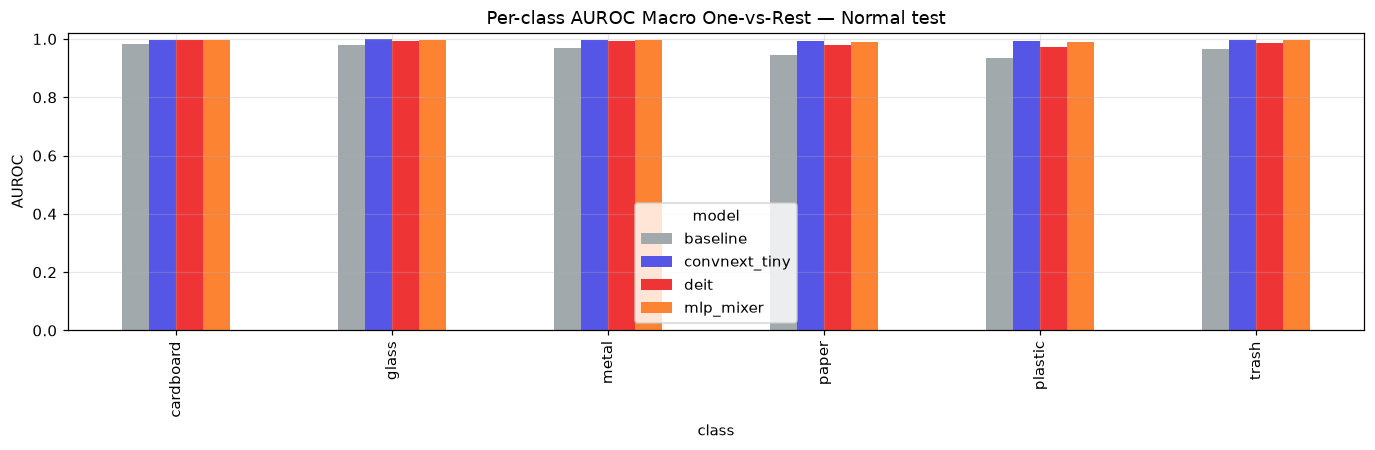

saved figures\per_class_auroc_custom_test.png


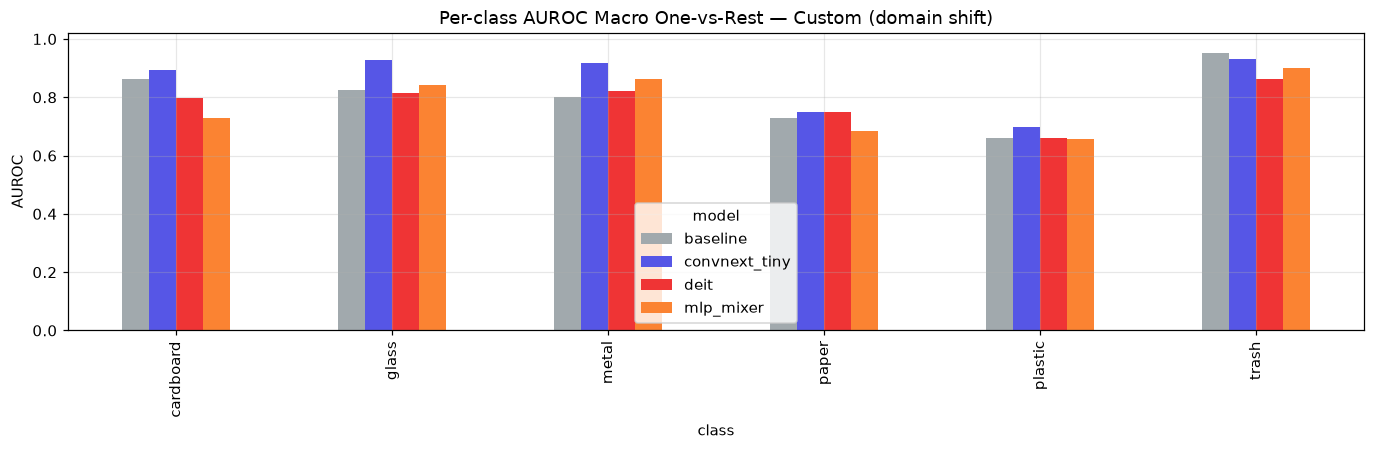

In [9]:
if not prob_metrics.empty:
    auroc_cols = [c for c in prob_metrics.columns
                  if c.startswith("auroc_") and c != "auroc_macro_ovr"]
    long = prob_metrics.melt(
        id_vars=["model", "split"], value_vars=auroc_cols,
        var_name="class", value_name="auroc")
    long["class"] = long["class"].str.replace("auroc_", "", regex=False)
    for split in SPLITS:
        sub = long[long.split == split]
        if sub["auroc"].notna().any():
            pivot = sub.pivot_table(index="class", columns="model", values="auroc")
            ax = pivot.plot(kind="bar", figsize=(1.6 * len(pivot) + 3, 4.2), color=ev.model_palette(pivot.columns))
            ax.set_ylabel("AUROC"); ax.set_ylim(0, 1.02)
            ax.set_title(f"Per-class AUROC Macro One-vs-Rest — {SPLITS[split]}"); ax.legend(title="model")
            fig = ax.get_figure(); fig.tight_layout()
            ev.savefig(fig, f"per_class_auroc_{split}", FIG_DIR, SAVE_FIGS); plt.show()
else:
    print("(no probability metrics to plot)")